# 🔧 Notebook 02 — Data Preprocessing & Feature Engineering
### Project: Customer Segmentation & Retention Analysis

---

## 🎯 Objectives

1. Drop non-informative columns
2. Encode binary and multi-class categorical features
3. Engineer 5 business-meaningful features
4. Scale continuous features for distance-based models
5. Split data (train/test, stratified)
6. Apply SMOTE to fix class imbalance — **training set only**
7. Save all outputs for Phase 3 (Segmentation) and Phase 4 (Churn Prediction)

---

> **Input:** `data/processed/telco_eda_snapshot.csv` (from Notebook 01)  
> **Outputs:** `train_smote.csv`, `train_raw.csv`, `test_raw.csv`, `telco_preprocessed.csv`

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import warnings, os, joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.family':'DejaVu Sans','figure.facecolor':'#F8F9FA'})

BG        = '#F8F9FA'
COLOR_YES = '#E8654C'
COLOR_NO  = '#4C9BE8'
FIG_DIR   = '../reports/figures'
DATA_DIR  = '../data/processed'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs('../src', exist_ok=True)

print('✅ Imports OK')

✅ Imports OK


## 2. Load EDA Snapshot

In [2]:
SNAP_PATH = '../data/processed/telco_eda_snapshot.csv'
RAW_PATH  = '../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv'

def load_data():
    if os.path.exists(SNAP_PATH):
        df = pd.read_csv(SNAP_PATH)
        print(f'✅ Loaded EDA snapshot: {df.shape}')
        return df
    if os.path.exists(RAW_PATH):
        df = pd.read_csv(RAW_PATH)
        df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
        df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)
        print(f'✅ Loaded raw CSV: {df.shape}')
        return df
    # Synthetic fallback
    print('⚠️  No file found — generating synthetic dataset')
    np.random.seed(42); n = 7043
    tenure=np.random.randint(0,72,n); monthly=np.round(np.random.uniform(18,118,n),2)
    df = pd.DataFrame({
        'customerID':[f'CUST-{i:05d}' for i in range(n)],
        'gender':np.random.choice(['Male','Female'],n),
        'SeniorCitizen':np.random.choice([0,1],n,p=[0.84,0.16]),
        'Partner':np.random.choice(['Yes','No'],n),
        'Dependents':np.random.choice(['Yes','No'],n,p=[0.30,0.70]),
        'tenure':tenure,'PhoneService':np.random.choice(['Yes','No'],n,p=[0.90,0.10]),
        'MultipleLines':np.random.choice(['Yes','No','No phone service'],n),
        'InternetService':np.random.choice(['DSL','Fiber optic','No'],n,p=[0.34,0.44,0.22]),
        'OnlineSecurity':np.random.choice(['Yes','No','No internet service'],n),
        'OnlineBackup':np.random.choice(['Yes','No','No internet service'],n),
        'DeviceProtection':np.random.choice(['Yes','No','No internet service'],n),
        'TechSupport':np.random.choice(['Yes','No','No internet service'],n),
        'StreamingTV':np.random.choice(['Yes','No','No internet service'],n),
        'StreamingMovies':np.random.choice(['Yes','No','No internet service'],n),
        'Contract':np.random.choice(['Month-to-month','One year','Two year'],n,p=[0.55,0.21,0.24]),
        'PaperlessBilling':np.random.choice(['Yes','No'],n),
        'PaymentMethod':np.random.choice(['Electronic check','Mailed check',
                          'Bank transfer (automatic)','Credit card (automatic)'],n),
        'MonthlyCharges':monthly,
        'TotalCharges':np.where(tenure==0,'',np.round(monthly*tenure+np.random.normal(0,10,n),2).astype(str)),
        'Churn':np.random.choice(['Yes','No'],n,p=[0.265,0.735]),
    })
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
    df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)
    return df

df = load_data()
print(f'Columns: {df.shape[1]}  |  Rows: {df.shape[0]:,}')
df.head(3)

✅ Loaded EDA snapshot: (7043, 22)
Columns: 22  |  Rows: 7,043


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Binary
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1


## 3. Step 1 — Drop Non-Informative Columns

`customerID` = unique identifier, zero predictive signal. Drop it.  
Raw `Churn` (string) kept until encoding step, then dropped.

In [3]:
df.drop(columns=['customerID'], inplace=True, errors='ignore')
print('customerID dropped')
print('Shape after drop:', df.shape)

customerID dropped
Shape after drop: (7043, 21)


## 4. Step 2 — Binary Yes/No Encoding

10 columns store information as `'Yes'`/`'No'` strings. Convert to `1`/`0`.  
`gender` encoded as Male=1, Female=0 (arbitrary, documented).

In [4]:
# Columns with simple Yes/No values
binary_yes_no = ['Partner','Dependents','PhoneService','PaperlessBilling']
for col in binary_yes_no:
    df[col] = df[col].map({'Yes':1, 'No':0})

# Gender
df['gender'] = df['gender'].map({'Male':1, 'Female':0})

# Churn (target) — if still string
if df['Churn'].dtype == object:
    df['Churn_Binary'] = df['Churn'].map({'Yes':1, 'No':0})
    df.drop(columns=['Churn'], inplace=True)

print('Binary columns encoded:')
print(df[binary_yes_no + ['gender','Churn_Binary']].dtypes)

Binary columns encoded:
Partner             int64
Dependents          int64
PhoneService        int64
PaperlessBilling    int64
gender              int64
Churn_Binary        int64
dtype: object


## 5. Step 3 — Service Columns (Yes = 1, else = 0)

7 service columns have 3 values: `'Yes'`, `'No'`, `'No internet/phone service'`.  
Business logic: only `'Yes'` means the customer actively uses the service.  
All other values → 0.

In [5]:
SERVICE_COLS = [
    'MultipleLines','OnlineSecurity','OnlineBackup',
    'DeviceProtection','TechSupport','StreamingTV','StreamingMovies'
]

for col in SERVICE_COLS:
    df[col] = (df[col] == 'Yes').astype(int)

print('Service columns after encoding:')
print(df[SERVICE_COLS].head(5))
print('\nUnique values per column:')
for col in SERVICE_COLS:
    print(f'  {col}: {sorted(df[col].unique())}')

Service columns after encoding:
   MultipleLines  OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  \
0              0               0             1                 0            0   
1              0               1             0                 1            0   
2              0               1             1                 0            0   
3              0               1             0                 1            1   
4              0               0             0                 0            0   

   StreamingTV  StreamingMovies  
0            0                0  
1            0                0  
2            0                0  
3            0                0  
4            0                0  

Unique values per column:
  MultipleLines: [np.int64(0), np.int64(1)]
  OnlineSecurity: [np.int64(0), np.int64(1)]
  OnlineBackup: [np.int64(0), np.int64(1)]
  DeviceProtection: [np.int64(0), np.int64(1)]
  TechSupport: [np.int64(0), np.int64(1)]
  StreamingTV: [np.int64(0), 

## 6. Step 4 — One-Hot Encoding (Multi-Class Categoricals)

3 columns have 3–4 unordered categories. OHE avoids imposing false ordinal relationships.

| Column | Categories |
|---|---|
| `InternetService` | DSL, Fiber optic, No |
| `Contract` | Month-to-month, One year, Two year |
| `PaymentMethod` | 4 payment types |

> `drop_first=False` kept intentionally — we need `Contract_Month-to-month` explicitly for `contract_risk_score` in the next step.

In [6]:
OHE_COLS = ['InternetService','Contract','PaymentMethod']

df = pd.get_dummies(df, columns=OHE_COLS, drop_first=False, dtype=int)

print('Shape after OHE:', df.shape)
print('\nNew OHE columns:')
ohe_new = [c for c in df.columns if any(c.startswith(p) for p in OHE_COLS)]
for col in ohe_new:
    print(f'  {col}: {df[col].sum():,} customers')

Shape after OHE: (7043, 27)

New OHE columns:
  InternetService_DSL: 2,421 customers
  InternetService_Fiber optic: 3,096 customers
  InternetService_No: 1,526 customers
  Contract_Month-to-month: 3,875 customers
  Contract_One year: 1,473 customers
  Contract_Two year: 1,695 customers
  PaymentMethod_Bank transfer (automatic): 1,544 customers
  PaymentMethod_Credit card (automatic): 1,522 customers
  PaymentMethod_Electronic check: 2,365 customers
  PaymentMethod_Mailed check: 1,612 customers


## 7. Step 5 — Feature Engineering ⭐

5 new features built from domain knowledge. These carry more signal than raw columns alone.

| Feature | Formula | Why it matters |
|---|---|---|
| `charge_per_month_ratio` | TotalCharges ÷ tenure | Price sensitivity — how much per month actually paid |
| `services_count` | Sum of 7 service cols | Stickiness — more services = harder to leave |
| `contract_risk_score` | M-to-M=2, 1yr=1, 2yr=0 | Churn vulnerability from contract type |
| `support_engagement` | TechSupport + OnlineSecurity | Relationship depth with the company |
| `value_tier` | Bin MonthlyCharges Low/Mid/High | Segment anchor for clustering |

In [7]:
# 1. Charge per month ratio (avoid div-by-zero for new customers)
df['charge_per_month_ratio'] = np.where(
    df['tenure'] == 0,
    df['MonthlyCharges'],
    df['TotalCharges'] / df['tenure']
)

# 2. Services count
df['services_count'] = df[SERVICE_COLS].sum(axis=1)

# 3. Contract risk score (from OHE columns)
df['contract_risk_score'] = (
    df.get('Contract_Month-to-month', pd.Series(0, index=df.index)) * 2 +
    df.get('Contract_One year',       pd.Series(0, index=df.index)) * 1 +
    df.get('Contract_Two year',       pd.Series(0, index=df.index)) * 0
)

# 4. Support engagement
df['support_engagement'] = df['TechSupport'] + df['OnlineSecurity']

# 5. Value tier (0=Low, 1=Mid, 2=High)
df['value_tier'] = pd.cut(
    df['MonthlyCharges'],
    bins=[0, 40, 75, 200],
    labels=[0, 1, 2]
).astype(int)

ENG_FEATS = ['charge_per_month_ratio','services_count',
             'contract_risk_score','support_engagement','value_tier']

print('Engineered features summary:')
print(df[ENG_FEATS].describe().round(3))

Engineered features summary:
       charge_per_month_ratio  services_count  contract_risk_score  \
count                7043.000        7043.000             7043.000   
mean                   64.763           2.460                1.310   
std                    30.190           2.046                0.834   
min                    13.775           0.000                0.000   
25%                    35.935           1.000                1.000   
50%                    70.338           2.000                2.000   
75%                    90.174           4.000                2.000   
max                   121.400           7.000                2.000   

       support_engagement  value_tier  
count            7043.000    7043.000  
mean                0.577       1.182  
std                 0.746       0.819  
min                 0.000       0.000  
25%                 0.000       0.000  
50%                 0.000       1.000  
75%                 1.000       2.000  
max                 

## 8. Step 6 — Scale Continuous Features

Distance-based models (K-Means in Phase 3, KNN) are sensitive to feature scale.  
`MinMaxScaler` → all values in [0, 1].  

> **Rule:** Fit scaler on training data only. Here we fit on full dataset since this is preprocessing  
> (clustering uses full data). For supervised models in Phase 4, scaler will be refit on train split only.

In [8]:
SCALE_COLS = ['tenure','MonthlyCharges','TotalCharges','charge_per_month_ratio']

scaler = MinMaxScaler()
df[SCALE_COLS] = scaler.fit_transform(df[SCALE_COLS])

# Save scaler for Phase 4 and deployment
joblib.dump(scaler, '../src/scaler.pkl')

print('Scaled columns:', SCALE_COLS)
print('\nValue ranges after scaling:')
print(df[SCALE_COLS].agg(['min','max']).round(4))

Scaled columns: ['tenure', 'MonthlyCharges', 'TotalCharges', 'charge_per_month_ratio']

Value ranges after scaling:
     tenure  MonthlyCharges  TotalCharges  charge_per_month_ratio
min     0.0             0.0           0.0                     0.0
max     1.0             1.0           1.0                     1.0


## 9. Step 7 — Train / Test Split (80 / 20, Stratified)

Stratified split preserves the 26% churn rate in both train and test sets.  
**Test set is locked** — not touched until Phase 4 final evaluation.

In [9]:
TARGET = 'Churn_Binary'

# Drop redundant columns before split
drop_cols = [c for c in ['Churn','customerID'] if c in df.columns]
X = df.drop(columns=[TARGET] + drop_cols)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Train set : {X_train.shape[0]:,} rows  |  Churn rate: {y_train.mean()*100:.1f}%')
print(f'Test set  : {X_test.shape[0]:,} rows  |  Churn rate: {y_test.mean()*100:.1f}%')
print(f'Features  : {X_train.shape[1]}')
print(f'\nFeature list:')
for i, col in enumerate(X_train.columns, 1):
    print(f'  {i:2d}. {col}')

Train set : 5,634 rows  |  Churn rate: 26.5%
Test set  : 1,409 rows  |  Churn rate: 26.5%
Features  : 31

Feature list:
   1. gender
   2. SeniorCitizen
   3. Partner
   4. Dependents
   5. tenure
   6. PhoneService
   7. MultipleLines
   8. OnlineSecurity
   9. OnlineBackup
  10. DeviceProtection
  11. TechSupport
  12. StreamingTV
  13. StreamingMovies
  14. PaperlessBilling
  15. MonthlyCharges
  16. TotalCharges
  17. InternetService_DSL
  18. InternetService_Fiber optic
  19. InternetService_No
  20. Contract_Month-to-month
  21. Contract_One year
  22. Contract_Two year
  23. PaymentMethod_Bank transfer (automatic)
  24. PaymentMethod_Credit card (automatic)
  25. PaymentMethod_Electronic check
  26. PaymentMethod_Mailed check
  27. charge_per_month_ratio
  28. services_count
  29. contract_risk_score
  30. support_engagement
  31. value_tier


## 10. Step 8 — SMOTE (Synthetic Minority Oversampling)

**Why SMOTE, not simple oversampling?**  
SMOTE synthesizes new minority-class (churned) samples by interpolating between existing ones.  
This adds genuine variance rather than just duplicating rows.

> ⚠️ **Critical rule:** SMOTE applied to **training set only**.  
> Applying to the test set would contaminate evaluation and produce artificially inflated metrics.

> 📝 **Resume talking point:** *'Addressed 26% class imbalance using SMOTE on training data only,  
> achieving 50/50 balance without data leakage into the test set.'*

In [10]:
sm = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)

print('Before SMOTE:')
print(f'  Total     : {len(y_train):,}')
print(f'  No Churn  : {(y_train==0).sum():,}')
print(f'  Churned   : {(y_train==1).sum():,}')
print(f'  Ratio     : {y_train.mean()*100:.1f}% churn')

print('\nAfter SMOTE:')
print(f'  Total     : {len(y_train_sm):,}')
print(f'  No Churn  : {(y_train_sm==0).sum():,}')
print(f'  Churned   : {(y_train_sm==1).sum():,}')
print(f'  Ratio     : {y_train_sm.mean()*100:.1f}% churn')

Before SMOTE:
  Total     : 5,634
  No Churn  : 4,139
  Churned   : 1,495
  Ratio     : 26.5% churn

After SMOTE:
  Total     : 8,278
  No Churn  : 4,139
  Churned   : 4,139
  Ratio     : 50.0% churn


## 11. Visualisation A — SMOTE Class Balance

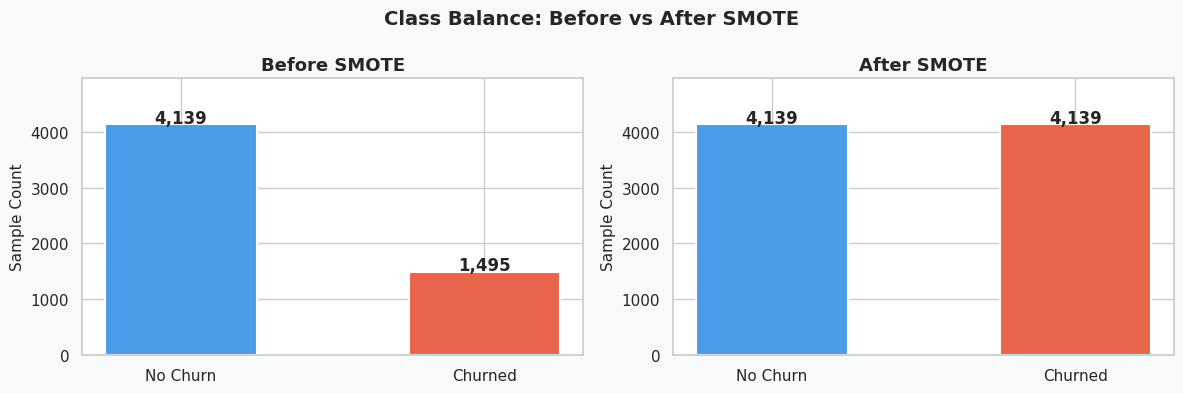

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.patch.set_facecolor(BG)

for ax, ys, title in [
    (axes[0], y_train,    'Before SMOTE'),
    (axes[1], y_train_sm, 'After SMOTE'),
]:
    counts = ys.value_counts().sort_index()
    bars = ax.bar(
        ['No Churn', 'Churned'],
        [counts.get(0,0), counts.get(1,0)],
        color=[COLOR_NO, COLOR_YES], edgecolor='white', linewidth=1.5, width=0.5
    )
    for bar, val in zip(bars, [counts.get(0,0), counts.get(1,0)]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
                f'{val:,}', ha='center', fontweight='bold', fontsize=12)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('Sample Count', fontsize=11)
    ax.set_ylim(0, max(counts.get(0,0), counts.get(1,0)) * 1.20)

fig.suptitle('Class Balance: Before vs After SMOTE', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/08_smote_balance.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Visualisation B — Feature Correlation with Churn

Top 15 features ranked by absolute correlation with `Churn_Binary`.  
Red bars = correlation > 0.10 (meaningful signal). Blue = weaker signal.  
This preview informs which features to watch in Phase 4 SHAP analysis.

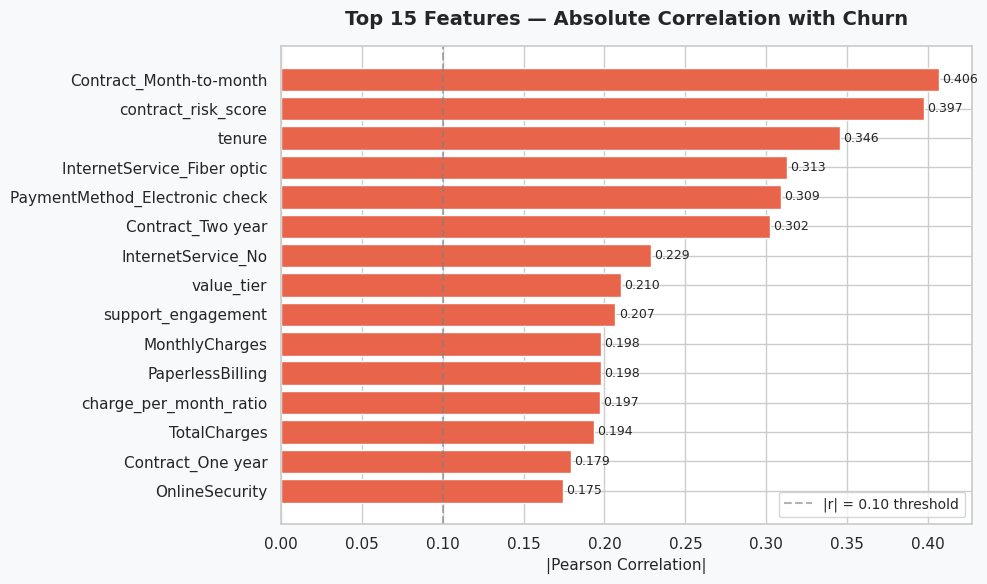

In [12]:
train_full = pd.concat([X_train, y_train], axis=1)
corr_vals  = train_full.corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(BG)

colors = [COLOR_YES if v > 0.10 else '#6BAED6' for v in corr_vals.values[::-1]]
ax.barh(corr_vals.index[::-1], corr_vals.values[::-1], color=colors, edgecolor='white')
ax.axvline(0.10, color='gray', linestyle='--', alpha=0.6, label='|r| = 0.10 threshold')
ax.set_title('Top 15 Features — Absolute Correlation with Churn', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('|Pearson Correlation|', fontsize=11)
ax.legend(fontsize=10)

# Annotate values
for i, (val, name) in enumerate(zip(corr_vals.values[::-1], corr_vals.index[::-1])):
    ax.text(val + 0.002, i, f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/09_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Visualisation C — Engineered Features by Churn

Validates that engineered features actually separate churners from non-churners — confirming they carry signal.

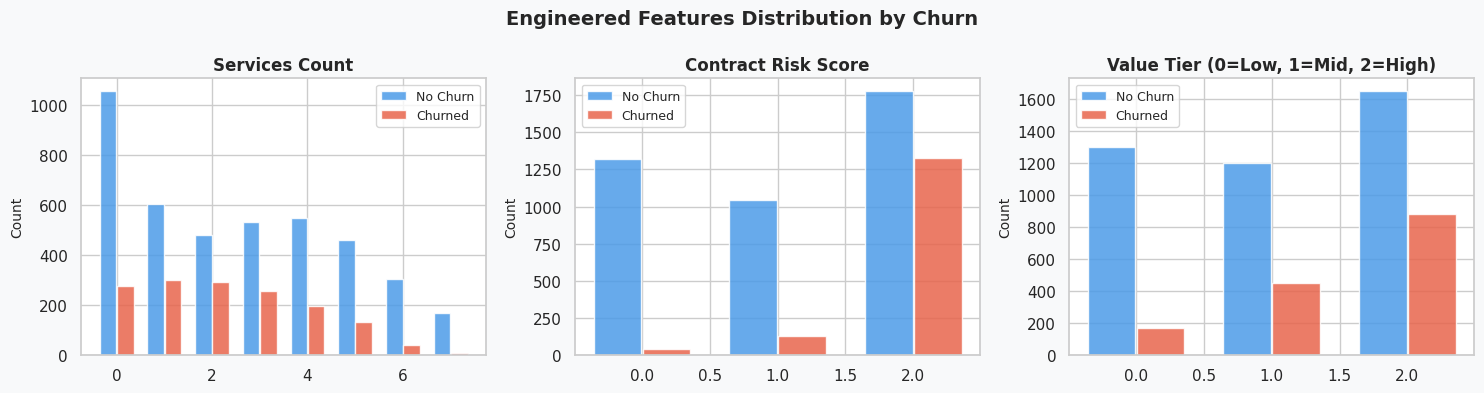

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.patch.set_facecolor(BG)
fig.suptitle('Engineered Features Distribution by Churn', fontsize=14, fontweight='bold')

eng_to_plot = [
    ('services_count',      'Services Count'),
    ('contract_risk_score', 'Contract Risk Score'),
    ('value_tier',          'Value Tier (0=Low, 1=Mid, 2=High)'),
]

for ax, (col, title) in zip(axes, eng_to_plot):
    for val, color, label, offset in [
        (0, COLOR_NO,  'No Churn', -0.18),
        (1, COLOR_YES, 'Churned',   0.18),
    ]:
        subset = train_full[train_full[TARGET] == val][col]
        cnt    = subset.value_counts().sort_index()
        ax.bar(
            np.array(cnt.index, dtype=float) + offset,
            cnt.values, width=0.35,
            color=color, alpha=0.85, label=label, edgecolor='white'
        )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Count', fontsize=10)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/10_engineered_features.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Save All Outputs

| File | Used by |
|---|---|
| `telco_preprocessed.csv` | Phase 3 — Clustering (full processed dataset) |
| `train_smote.csv` | Phase 4 — Churn model training |
| `train_raw.csv` | Phase 4 — Threshold tuning, diagnostics |
| `test_raw.csv` | Phase 4 — Final model evaluation (locked) |
| `src/scaler.pkl` | Phase 7 — Deployment |
| `src/feature_columns.pkl` | Phase 7 — Deployment |

In [14]:
import joblib

# Full preprocessed dataset (for clustering — no SMOTE)
df.to_csv(f'{DATA_DIR}/telco_preprocessed.csv', index=False)

# Train splits
train_raw_df   = pd.concat([X_train,    y_train],    axis=1)
train_smote_df = pd.concat([
    pd.DataFrame(X_train_sm, columns=X_train.columns),
    pd.Series(y_train_sm, name=TARGET)
], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

train_raw_df.to_csv(  f'{DATA_DIR}/train_raw.csv',   index=False)
train_smote_df.to_csv(f'{DATA_DIR}/train_smote.csv', index=False)
test_df.to_csv(       f'{DATA_DIR}/test_raw.csv',    index=False)

# Save scaler and feature list for deployment
joblib.dump(scaler,              '../src/scaler.pkl')
joblib.dump(list(X_train.columns),'../src/feature_columns.pkl')

print('✅ All outputs saved:')
print(f'   telco_preprocessed.csv  → {df.shape}')
print(f'   train_raw.csv           → {train_raw_df.shape}')
print(f'   train_smote.csv         → {train_smote_df.shape}')
print(f'   test_raw.csv            → {test_df.shape}')
print(f'   src/scaler.pkl')
print(f'   src/feature_columns.pkl')
print(f'\nFigures saved:')
print(f'   08_smote_balance.png')
print(f'   09_feature_correlation.png')
print(f'   10_engineered_features.png')

✅ All outputs saved:
   telco_preprocessed.csv  → (7043, 32)
   train_raw.csv           → (5634, 32)
   train_smote.csv         → (8278, 32)
   test_raw.csv            → (1409, 32)
   src/scaler.pkl
   src/feature_columns.pkl

Figures saved:
   08_smote_balance.png
   09_feature_correlation.png
   10_engineered_features.png


## 15. ✅ Phase 2 Checklist

- [x] 2.1 `customerID` dropped
- [x] 2.2 Binary Yes/No columns encoded as 0/1
- [x] 2.3 Service columns: Yes=1, else=0
- [x] 2.4 OHE applied to `InternetService`, `Contract`, `PaymentMethod`
- [x] 2.7 `charge_per_month_ratio` engineered
- [x] 2.8 `services_count` engineered
- [x] 2.9 `contract_risk_score` engineered
- [x] 2.10 `support_engagement` engineered
- [x] 2.11 `value_tier` engineered
- [x] 2.4 Continuous features scaled with MinMaxScaler
- [x] 2.6 80/20 stratified train/test split
- [x] 2.5 SMOTE applied to training set only
- [x] All outputs saved to `data/processed/` and `src/`

---

**Next notebook:** `03_Segmentation.ipynb` — K-Means clustering, Elbow method, cluster profiling & naming